In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import seaborn as sns

In [13]:
w, beta, g, tau_a, I, eta = 0.8, 1.0, 2.0, 120.0, 1.3, 1000.0

def h(x):
    return 0.5*(1 + np.tanh(0.5*eta*x))   # stable form of 1/(1+exp(-eta x))

def rhs(t, y):
    uL, uR, aL, aR = y
    return [-uL + h(w*uL - beta*uR - g*aL + I),
            -uR + h(w*uR - beta*uL - g*aR + I),
            (-aL + uL)/tau_a,
            (-aR + uR)/tau_a]

In [15]:
sol = solve_ivp(rhs, [0, 30*tau_a], [1, 0, 0, 0],
                method="Radau", rtol=1e-8, atol=1e-10,
                dense_output=True)

In [141]:
def dom_periods(sol):
    u_l = sol.y[0]
    u_r = sol.y[1]
    t = sol.t
    
    # figure out when neither is dominant
    middle = np.abs(u_l - u_r) < 1/2
    switch_idx = np.where(np.diff(middle.astype(int) != 0))
    switch_idx = np.insert(switch_idx, 0,0)

    # find the difference between these times: some are intermediate times
    dom_times = np.diff(t[switch_idx])
    dom_times = dom_times[4:]
    dom_times = dom_times[dom_times > 5]
    # isolate L and R dominance
    L_dom = dom_times[::2]
    R_dom = dom_times[1::2]

    return L_dom, R_dom
    

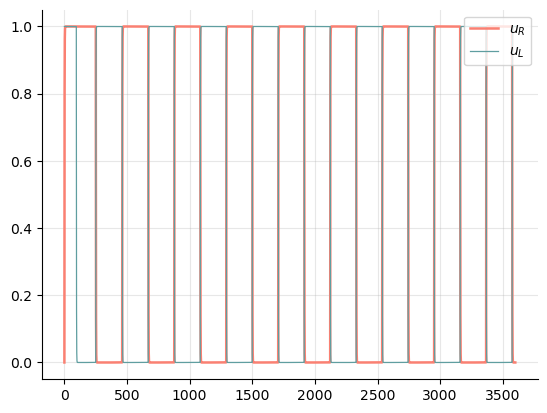

In [179]:
plt.plot(sol.t, sol.y[1], label = r"$u_R$", color = "salmon", linewidth = 1.8)
plt.plot(sol.t, sol.y[0], label = r"$u_L$", color = "cadetblue", linewidth = .9)
plt.grid(alpha = .3)
sns.despine()
plt.legend(loc = "upper right")
plt.savefig("rivarly1", dpi = 300, bbox_inches = "tight")
plt.show()

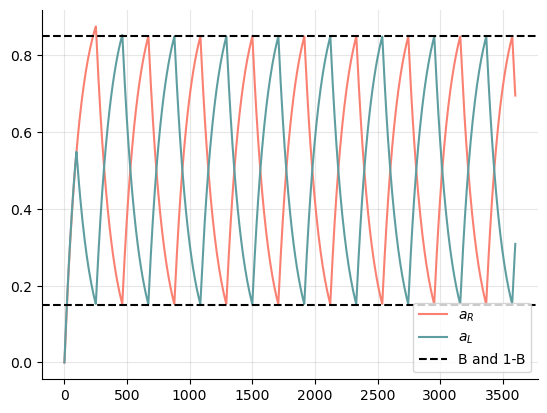

In [181]:
plt.plot(sol.t, sol.y[3], label = r"$a_R$", color = "salmon")
plt.plot(sol.t, sol.y[2], label = r"$a_L$", color = "cadetblue")
plt.axhline(y = .15, linestyle = "--", color = "black", label = "B and 1-B")
plt.axhline(y = .85, linestyle = "--", color = "black")
plt.grid(alpha = .3)
sns.despine()
plt.legend(loc = "lower right")
plt.savefig("rivarly2", dpi = 300, bbox_inches = "tight")
plt.show()

In [139]:
## part ii)
## now I need to measure the mean dominance times for different inputs

In [143]:
def rhs1(t, y):
    uL, uR, aL, aR = y
    return [-uL + h(w*uL - beta*uR - g*aL + 1.3),
            -uR + h(w*uR - beta*uL - g*aR + 1.3),
            (-aL + uL)/tau_a,
            (-aR + uR)/tau_a]

def rhs2(t, y):
    uL, uR, aL, aR = y
    return [-uL + h(w*uL - beta*uR - g*aL + 1.45),
            -uR + h(w*uR - beta*uL - g*aR + 1.3),
            (-aL + uL)/tau_a,
            (-aR + uR)/tau_a]

def rhs3(t, y):
    uL, uR, aL, aR = y
    return [-uL + h(w*uL - beta*uR - g*aL + 1.6),
            -uR + h(w*uR - beta*uL - g*aR + 1.3),
            (-aL + uL)/tau_a,
            (-aR + uR)/tau_a]

In [145]:
sol1 = solve_ivp(rhs1, [0, 30*tau_a], [1, 0, 0, 0],
                method="Radau", rtol=1e-8, atol=1e-10,
                dense_output=True)

sol2 = solve_ivp(rhs2, [0, 30*tau_a], [1, 0, 0, 0],
                method="Radau", rtol=1e-8, atol=1e-10,
                dense_output=True)

sol3 = solve_ivp(rhs3, [0, 30*tau_a], [1, 0, 0, 0],
                method="Radau", rtol=1e-8, atol=1e-10,
                dense_output=True)

In [147]:
L1, R1 = dom_periods(sol1)
L2, R2 = dom_periods(sol2)
L3, R3 = dom_periods(sol3)

domL1, domR1, domL2, domR2, domL3, domR3 = np.mean(L1), np.mean(R1), np.mean(L2), np.mean(R2), np.mean(L3), np.mean(R3)

In [155]:
print(domL1, domR1)
print(domL2, domR2)
print(domL3, domR3)

206.86606073030356 206.4795742489307
159.3630260013226 196.087408902063
125.48902327848923 184.81531821746484


In [ ]:
## part iii)
# now we edit the weight w, see how this changes T_dom

In [157]:
def rhs4(t, y):
    uL, uR, aL, aR = y
    return [-uL + h(.3*uL - beta*uR - g*aL + I),
            -uR + h(.3*uR - beta*uL - g*aR + I),
            (-aL + uL)/tau_a,
            (-aR + uR)/tau_a]

sol4 = solve_ivp(rhs4, [0, 30*tau_a], [1, 0, 0, 0],
                method="Radau", rtol=1e-8, atol=1e-10,
                dense_output=True)

In [163]:
L4, R4 = dom_periods(sol4)
domL4, domR4 = np.mean(L4), np.mean(R4)
print(domL4, domR4)

165.93612670379235 165.77748710311718


In [169]:
120*np.log(1.6/.4)

166.35532333438687

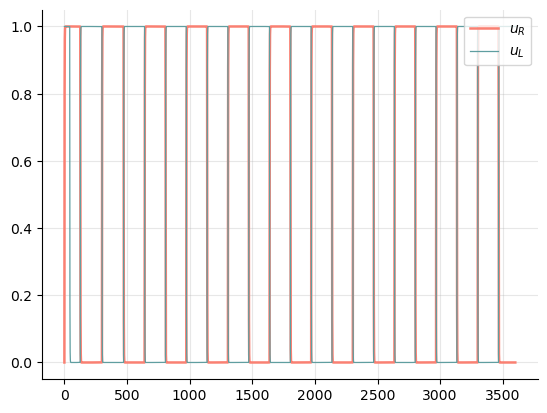

In [175]:
plt.plot(sol4.t, sol4.y[1], label = r"$u_R$", color = "salmon", linewidth = 1.8)
plt.plot(sol4.t, sol4.y[0], label = r"$u_L$", color = "cadetblue", linewidth = .9)
plt.grid(alpha = .3)
sns.despine()
plt.legend(loc = "upper right")
plt.savefig("rivarly3", dpi = 300, bbox_inches = "tight")
plt.show()

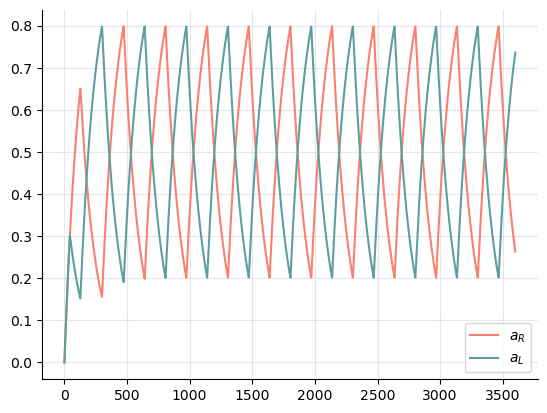

In [177]:
plt.plot(sol4.t, sol4.y[3], label = r"$a_R$", color = "salmon")
plt.plot(sol4.t, sol4.y[2], label = r"$a_L$", color = "cadetblue")
plt.grid(alpha = .3)
sns.despine()
plt.legend(loc = "lower right")
plt.savefig("rivarly4", dpi = 300, bbox_inches = "tight")
plt.show()